# Modelamiento — riesgo por segmento de calle (Eje 2)

| | |
|---|---|
| **Objetivo** | estimar cuántos eventos callejeros (robo, hurto, acoso, agresión sexual, violencia física) habrá en cada segmento en un año, **corrigiendo por cobertura de coordenadas** |
| **Grano** | segmento de calle × año objetivo (`features/panel_train.parquet`: objetivos 2019–2022, y `panel_valid.parquet`: objetivo 2023) |
| **Validación** | **ventanas móviles**: para cada año 2021, 2022 y 2023 se entrena con los años anteriores y se evalúa en ese año. Hiperparámetros con un corte interno (entrena ≤ 2021, ajusta 2022) |
| **Reglas de decisión (fijadas antes de mirar resultados)** | el modelo es el de **menor deviance media** en las ventanas; un bloque de features se conserva solo si **baja la deviance media**; el valor de λ se elige en `ruteo_seguro_pesos` con una regla explícita |
| **Test** | enero–agosto de 2024: se abre **una sola vez**, en la sección 7, con los modelos ya fijados |
| **Salidas** | `models/eje2/` (modelos + manifest), `outputs/riesgo_*.parquet`, `outputs/indice_puntos_acceso.parquet`, métricas en CSV |
| **Documento** | `docs/Model_Eje2.md` |

In [1]:
import json, sys, warnings, joblib
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve().parents[2]
sys.path.insert(0, str(RAIZ / "code" / "eje2"))
import eje2_common as C, eje2_features as FE

BASE = RAIZ / "data_processed" / "eje2"; FEAT, CLEAN, SPL, GRAPH = BASE / "features", BASE / "clean", BASE / "splits", BASE / "graph"
OUTD = BASE / "outputs"; MODD = RAIZ / "models" / "eje2"; FIGS = RAIZ / "docs" / "images"
for p in (OUTD, MODD, FIGS): p.mkdir(parents=True, exist_ok=True)
SEED = 0
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
AZUL, ROJO, GRIS = "#1f4fd8", "#d64545", "#8a94a6"
def guardar_fig(n): plt.savefig(FIGS / n, bbox_inches="tight"); plt.show()

# --- métricas -----------------------------------------------------------------
def dev_poisson(y, mu):
    mu = np.clip(mu, 1e-9, None); t = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0.0)
    return float(2 * np.mean(t - (y - mu)))
def captura_top(y, score, frac):
    k = max(int(len(y) * frac), 1); return float(y[np.argsort(-score, kind="stable")[:k]].sum() / max(y.sum(), 1))
def evaluar(nombre, d, r, y="y_total"):
    # r = tasa anual corregida por cobertura; mu = r * exposición
    mu = r * d.expo.values; yy = d[y].values
    return {"modelo": nombre, "deviance": round(dev_poisson(yy, mu), 4), "MAE_conteo": round(float(np.mean(np.abs(yy - mu))), 4),
            "spearman": round(float(spearmanr(r, yy).statistic), 3), "captura_top5%": round(captura_top(yy, r, .05), 3),
            "captura_top10%": round(captura_top(yy, r, .10), 3), "eventos_pred/obs": round(float(mu.sum() / max(yy.sum(), 1)), 3)}

## 1. Carga — ¿qué vamos a hacer?

Leer el panel de train y de valid y unirlos en `full_tv` (objetivos 2019–2023), que es de donde salen las ventanas móviles. **No** se lee `test.parquet` ni `reserva.parquet`
(solo el manifest). Definir las columnas: numéricas (tasas históricas, vecindad, largo, POIs) y categórica (tipo de vía). Las features ya vienen calculadas "solo con el pasado".

In [2]:
tr = pd.read_parquet(FEAT / "panel_train.parquet"); va = pd.read_parquet(FEAT / "panel_valid.parquet")
full_tv = pd.concat([tr, va], ignore_index=True)
POI = [c for c in tr.columns if c.startswith("poi_")]
NUM = ["tasa_all", "tasa_prev", "decay", "tasa_pat", "tasa_per", "frac_noche", "vec1", "vec2", "n_vec1", "prior_vec", "length_m"] + POI
VIAS = sorted(tr.via.unique())
man = json.loads((SPL / "manifest.json").read_text())["splits"]
print(f"train {len(tr):,} filas (objetivos {sorted(map(int, tr.anio_obj.unique()))}) · valid {len(va):,} (objetivo {sorted(map(int, va.anio_obj.unique()))})")
print("test sellado:", man["test"]["filas"], "filas denuncias, ", man["test"]["desde"][:10], "->", man["test"]["hasta"][:10], "(solo manifest)")
print("features numéricas:", len(NUM), "· POIs:", POI)
print(f"\nY total: media por segmento-año {full_tv.y_total.mean():.3f} · % con >=1 evento: {(full_tv.y_total>0).mean():.1%}")
print("tasa observada ajustada (eventos/exposición) por año:"); print((full_tv.groupby('anio_obj').y_total.sum() / full_tv.groupby('anio_obj').expo.sum()).round(4).to_string())

train 586,428 filas (objetivos [2019, 2020, 2021, 2022]) · valid 146,607 (objetivo [2023])
test sellado: 283138 filas denuncias,  2024-01-01 -> 2024-08-31 (solo manifest)
features numéricas: 20 · POIs: ['poi_banco', 'poi_bar_ocio', 'poi_comercio', 'poi_educacion', 'poi_mercado', 'poi_paradero_bus', 'poi_parque', 'poi_restaurante', 'poi_salud']

Y total: media por segmento-año 0.251 · % con >=1 evento: 8.8%
tasa observada ajustada (eventos/exposición) por año:
anio_obj
2019    0.3571
2020    0.1869
2021    0.2452
2022    0.3178
2023    0.5287


### Qué encontramos (carga)

- Train: 586 428 filas (objetivos 2019–2022); valid: 146 607 (objetivo 2023). 20 features numéricas (11 de historial, vecindad y largo, más 9 conteos de POIs) y el tipo de vía.
- Solo **8,8 %** de los segmentos-año tienen al menos un evento; la media es 0,251 eventos por segmento-año.
- La tasa observada ajustada por exposición **sube con el tiempo**: 0,357 (2019), 0,187 (2020, pandemia), 0,245, 0,318 y **0,529 (2023)**, un salto de 66 % en el último año. Ya está corregida por cobertura, así que el nivel de un año se explica sobre todo con la tasa del año anterior.

**Decisión:** evaluar con deviance de Poisson (respeta que es un conteo disperso) y con captura top-k, que es lo que importa para ordenar calles. El test (283 138 denuncias, enero–agosto de 2024) no se abre aquí.

## 2. Hiperparámetros con un corte interno — ¿qué vamos a hacer?

Los modelos a comparar predicen una **tasa anual** corregida por cobertura; el conteo esperado es `tasa × exposición`:

| Modelo | Idea |
|---|---|
| B0 constante | la misma tasa para toda calle |
| B1 historial | tasa histórica ponderada del propio segmento |
| B2 Empirical Bayes | historial **suavizado** hacia el promedio de las calles vecinas; peso `n/(n+K)` |
| M1 GLM Poisson | regresión Poisson regularizada sobre log(1+features) |
| M2 LightGBM Poisson | árboles con `init_score = log(exposición)` |

Se eligen **K** (B2), **α** (M1) y el **número de iteraciones** (M2) con un corte interno: **entrena con objetivos ≤ 2021 y ajusta en 2022**. Esos valores quedan fijos para todas las ventanas.

In [3]:
EPS = 0.002                                   # tasa mínima anual (evita deviance infinita)
ent, aju = full_tv[full_tv.anio_obj <= 2021], full_tv[full_tv.anio_obj == 2022]
def r_b1(d): return np.maximum(12 * d.tasa_all.values, EPS)
def r_b2(d, K):
    w = d.n_eventos_pasado.values / (d.n_eventos_pasado.values + K)
    return np.maximum(12 * (w * d.tasa_all.values + (1 - w) * d.prior_vec.values), EPS)
Ks = [0.5, 1, 2, 4, 8, 16, 32]
devK = {K: dev_poisson(aju.y_total.values, r_b2(aju, K) * aju.expo.values) for K in Ks}
K_EB = min(devK, key=devK.get); print("deviance EB por K (ajuste 2022):", {k: round(v, 4) for k, v in devK.items()}, "-> K =", K_EB)
def X_glm(d, sc=None):
    X = np.log1p(d[NUM].fillna(0).clip(lower=0).values)
    X = np.c_[X, pd.get_dummies(d.via).reindex(columns=VIAS, fill_value=0).values.astype(float), d.frac_noche.isna().astype(float).values]
    if sc is None: sc = StandardScaler().fit(X)
    return sc.transform(X), sc
alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
Xe, sc0 = X_glm(ent); Xa, _ = X_glm(aju, sc0); devA = {}
for a in alphas:
    g = PoissonRegressor(alpha=a, max_iter=400).fit(Xe, ent.y_total.values / ent.expo.values, sample_weight=ent.expo.values)
    devA[a] = dev_poisson(aju.y_total.values, g.predict(Xa) * aju.expo.values)
A_GLM = min(devA, key=devA.get); print("deviance GLM por alpha (ajuste 2022):", {k: round(v, 4) for k, v in devA.items()}, "-> alpha =", A_GLM)

deviance EB por K (ajuste 2022): {0.5: 0.9605, 1: 0.9677, 2: 0.9803, 4: 1.0002, 8: 1.0295, 16: 1.0705, 32: 1.1252} -> K = 0.5


deviance GLM por alpha (ajuste 2022): {0.0001: 0.838, 0.001: 0.8383, 0.01: 0.8396, 0.1: 0.8463, 1.0: 0.9359} -> alpha = 0.0001


**Lectura (hiperparámetros del corte interno, ajuste en 2022):** el mejor K de Empirical Bayes es 0,5 (casi sin suavizado) y el mejor α del GLM es 1e-4 (casi sin regularización).

**Siguiente paso:** LightGBM Poisson con parada temprana usando 2022 como ajuste.

In [4]:
def mat_lgb(d):
    X = d[NUM].copy(); X["via"] = pd.Categorical(d.via, categories=VIAS); return X
PARAMS = dict(objective="poisson", learning_rate=0.05, num_leaves=31, min_data_in_leaf=200, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, seed=SEED, verbose=-1, num_threads=4)
def lgb_fit(d_ent, d_aju=None, y="y_total", n_iter=None):
    dt = lgb.Dataset(mat_lgb(d_ent), np.asarray(d_ent[y], dtype=float), init_score=np.log(np.asarray(d_ent.expo, dtype=float)))
    if d_aju is not None:
        dv = lgb.Dataset(mat_lgb(d_aju), np.asarray(d_aju[y], dtype=float), init_score=np.log(np.asarray(d_aju.expo, dtype=float)), reference=dt)
        return lgb.train(PARAMS, dt, 2000, valid_sets=[dv], callbacks=[lgb.early_stopping(60, verbose=False)])
    return lgb.train(PARAMS, dt, n_iter)
m_int = lgb_fit(ent, aju); N_IT = int(m_int.best_iteration * 1.15)
print(f"LightGBM: mejor iteración en el corte interno = {m_int.best_iteration} -> se usará {N_IT} (×1,15 porque el entrenamiento final tiene más datos)")

LightGBM: mejor iteración en el corte interno = 351 -> se usará 403 (×1,15 porque el entrenamiento final tiene más datos)


### Qué encontramos (hiperparámetros del corte interno)

- **Empirical Bayes:** el mejor K es el menor de la grilla (0,5; deviance 0,9605 frente a 0,9677 con K = 1): casi no conviene suavizar hacia las calles vecinas cuando el segmento tiene historia propia.
- **GLM Poisson:** el mejor α es 1e-4 (deviance 0,838); con α = 1,0 sube a 0,936. Casi sin regularización.
- **LightGBM:** la mejor iteración con ajuste en 2022 es 351; se usarán **403** (×1,15).

**Decisión:** K = 0,5, α = 1e-4 y 403 iteraciones quedan fijos para todas las ventanas y el test.

## 3. Ventanas móviles y elección del modelo — ¿qué vamos a hacer?

Una sola ventana puede favorecer a un modelo por azar (2020 fue pandemia, 2023 fue un año de alza). Por eso se evalúa **tres veces**, siempre entrenando solo con años anteriores:

| Ventana | Entrena con objetivos | Evalúa en |
|---|---|---|
| 1 | 2019–2020 | 2021 |
| 2 | 2019–2021 | 2022 |
| 3 | 2019–2022 | 2023 |

**Regla fijada de antemano:** el modelo de producción es el entrenable (M1 GLM o M2 LightGBM) con **menor deviance media** en las tres ventanas. B0, B1 y B2 son líneas base.

In [5]:
class Modelo:
    """Envoltura mínima: ajusta M1 (GLM Poisson) o M2 (LightGBM Poisson) a un objetivo y devuelve tasas anuales corregidas por cobertura."""
    def __init__(self, nombre, d, y="y_total"):
        self.nombre = nombre
        if nombre == "M1":
            X, self.sc = X_glm(d); self.g = PoissonRegressor(alpha=A_GLM, max_iter=400).fit(X, d[y].values / d.expo.values, sample_weight=d.expo.values)
        else:
            self.g = lgb_fit(d, None, y, N_IT)
    def predict(self, b):
        return np.maximum(self.g.predict(X_glm(b, self.sc)[0]) if self.nombre == "M1" else self.g.predict(mat_lgb(b)), EPS)

def ventana(F):
    a, b = full_tv[full_tv.anio_obj < F], full_tv[full_tv.anio_obj == F]
    m1, m2 = Modelo("M1", a), Modelo("M2", a)
    filas = [evaluar("B0 constante", b, np.full(len(b), a.y_total.sum() / a.expo.sum())), evaluar("B1 historial del segmento", b, r_b1(b)),
             evaluar(f"B2 Empirical Bayes (K={K_EB})", b, r_b2(b, K_EB)), evaluar("M1 GLM Poisson", b, m1.predict(b)), evaluar("M2 LightGBM Poisson", b, m2.predict(b))]
    return pd.DataFrame(filas).assign(ventana=F), {"M1": m1, "M2": m2}
folds = {}; M23 = None
for F_ in (2021, 2022, 2023):
    folds[F_], mods = ventana(F_)
    if F_ == 2023: M23 = mods                                    # modelos entrenados solo con objetivos <= 2022 (para las secciones siguientes)
roll = pd.concat(folds.values())
dev = roll.pivot(index="modelo", columns="ventana", values="deviance"); dev["media"] = dev.mean(axis=1); dev["desv_est"] = dev[[2021, 2022, 2023]].std(axis=1)
print("DEVIANCE por ventana (menor es mejor):"); print(dev.round(4).to_string())
for met in ("captura_top5%", "captura_top10%", "spearman", "eventos_pred/obs"):
    t = roll.pivot(index="modelo", columns="ventana", values=met); t["media"] = t.mean(axis=1); print(f"\n{met.upper()}:"); print(t.round(3).to_string())
roll.to_csv(OUTD / "ventanas_moviles.csv", index=False)
ELEGIDO = min(("M1", "M2"), key=lambda k: dev.loc["M1 GLM Poisson" if k == "M1" else "M2 LightGBM Poisson", "media"])
print("\nREGLA -> modelo de producción:", {"M1": "M1 GLM Poisson", "M2": "M2 LightGBM Poisson"}[ELEGIDO])

DEVIANCE por ventana (menor es mejor):
ventana                       2021    2022    2023   media  desv_est
modelo                                                              
B0 constante                1.2466  1.6954  2.9497  1.9639    0.8827
B1 historial del segmento   0.8027  0.9507  1.5163  1.0899    0.3766
B2 Empirical Bayes (K=0.5)  0.8485  0.9605  1.3786  1.0625    0.2794
M1 GLM Poisson              0.6606  0.8380  1.2663  0.9216    0.3114
M2 LightGBM Poisson         0.5863  0.7173  1.0554  0.7863    0.2420

CAPTURA_TOP5%:
ventana                      2021   2022   2023  media
modelo                                                
B0 constante                0.042  0.039  0.037  0.039
B1 historial del segmento   0.594  0.602  0.615  0.604
B2 Empirical Bayes (K=0.5)  0.523  0.531  0.551  0.535
M1 GLM Poisson              0.610  0.594  0.615  0.606
M2 LightGBM Poisson         0.614  0.620  0.639  0.624

CAPTURA_TOP10%:
ventana                      2021   2022   2023  media
model

**Lectura (ventanas móviles):** LightGBM tiene la menor deviance en 2021, 2022 y 2023 (media 0,786) y la menor dispersión entre ventanas; la regla elige M2. El detalle está en 'Qué encontramos (ventanas móviles)'.

**Siguiente paso:** graficar deviance y captura del top 5 % por ventana.

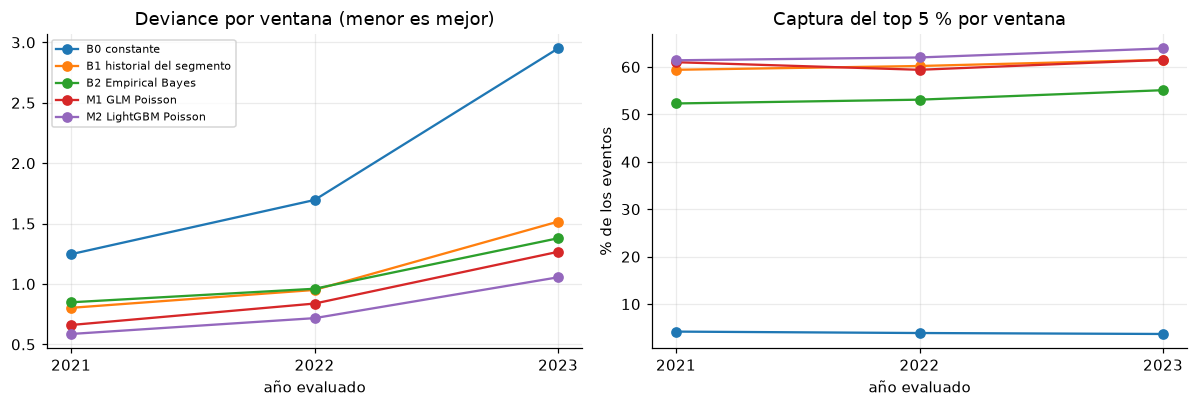

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre, g in roll.groupby("modelo"):
    ax[0].plot(g.ventana, g.deviance, "o-", label=nombre.split(" (")[0]); ax[1].plot(g.ventana, g["captura_top5%"] * 100, "o-", label=nombre.split(" (")[0])
ax[0].set(title="Deviance por ventana (menor es mejor)", xlabel="año evaluado", xticks=[2021, 2022, 2023]); ax[1].set(title="Captura del top 5 % por ventana", xlabel="año evaluado", ylabel="% de los eventos", xticks=[2021, 2022, 2023])
ax[0].legend(fontsize=7); plt.tight_layout(); guardar_fig("modelo_ventanas_moviles.png")

### Qué encontramos (ventanas móviles)

Deviance (menor es mejor):

| Modelo | 2021 | 2022 | 2023 | **Media** | Desv. est. |
|---|---:|---:|---:|---:|---:|
| B0 constante | 1,247 | 1,695 | 2,950 | 1,964 | 0,883 |
| B1 historial del segmento | 0,803 | 0,951 | 1,516 | 1,090 | 0,377 |
| B2 Empirical Bayes | 0,849 | 0,961 | 1,379 | 1,063 | 0,279 |
| M1 GLM Poisson | 0,661 | 0,838 | 1,266 | 0,922 | 0,311 |
| **M2 LightGBM Poisson** | **0,586** | **0,717** | **1,055** | **0,786** | **0,242** |

- **LightGBM gana en las tres ventanas** y tiene la menor dispersión. Su deviance media es 28 % menor que la del historial y 15 % menor que la del GLM.
- **Captura del top 5 % (media de las 3 ventanas):** LightGBM 62,4 %, GLM 60,6 %, historial 60,4 %, Empirical Bayes 53,5 %. En el top 10 %: 74,1 %, 73,5 %, 73,2 % y 66,2 %.
- **El historial ordena mejor el conjunto completo** (Spearman medio 0,442 frente a 0,384 de LightGBM), pero eso no se traduce en mejor deviance ni en mejor captura del top.
- **El nivel de eventos no es estable:** LightGBM predice 58 %, 65 % y 56 % de lo observado en 2021, 2022 y 2023; el GLM, 56 %, 56 % y 47 %. Cada año tuvo una tasa más alta que la historia previa (el salto de 2023 fue de 66 %), y ningún modelo lo anticipa.

**Regla aplicada:** el modelo de producción es el de menor deviance media entre M1 y M2 → **M2 LightGBM Poisson**.

![Ventanas móviles](../../../docs/images/modelo_ventanas_moviles.png)

## 4. Qué pesa en el modelo y ablaciones — ¿qué vamos a hacer?

(a) Qué features usa LightGBM; (b) si los **POIs** (flujo de gente / uso del suelo), la **vecindad** y el **largo** aportan de verdad. Se reentrena LightGBM sin cada bloque en **las tres ventanas** y se compara la deviance media.
**Regla fijada de antemano:** un bloque se conserva solo si la deviance media **con** el bloque es menor que **sin** él.

Importancia (ganancia) del modelo de la ventana 2023:
tasa_prev     0.404
tasa_all      0.278
decay         0.167
vec2          0.048
length_m      0.031
tasa_per      0.011
prior_vec     0.011
frac_noche    0.010
vec1          0.009
tasa_pat      0.008
via           0.006
n_vec1        0.005



Ablaciones (LightGBM, deviance media en 2021–2023):
                       deviance_media   v2021   v2022   v2023  cambio_vs_completo  se_conserva_el_bloque
completo                       0.7863  0.5863  0.7173  1.0554              0.0000                  False
sin POIs                       0.7867  0.5908  0.7152  1.0541              0.0004                   True
sin vecindad                   0.8121  0.6142  0.7376  1.0844              0.0257                   True
sin largo                      0.8039  0.6060  0.7321  1.0736              0.0176                   True
solo historial propio          0.8356  0.6464  0.7528  1.1076              0.0493                   True


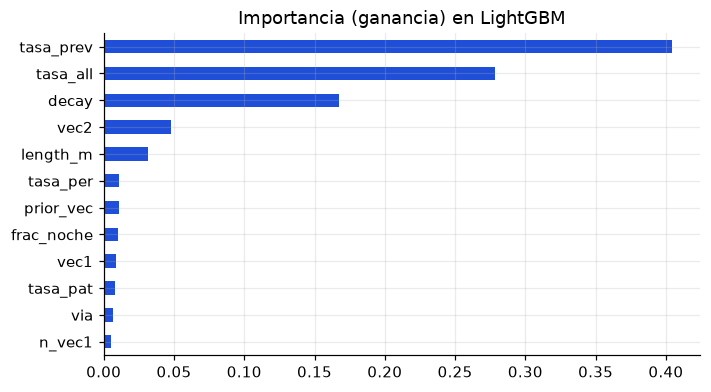

In [7]:
gbm = M23["M2"].g
imp = pd.Series(gbm.feature_importance("gain"), index=gbm.feature_name()).sort_values(ascending=False)
print("Importancia (ganancia) del modelo de la ventana 2023:"); print((imp / imp.sum()).round(3).head(12).to_string())
def dev_media_sin(cols_fuera):
    global NUM
    bak = NUM; NUM = [c for c in NUM if c not in cols_fuera]; ds = []
    try:
        for F_ in (2021, 2022, 2023):
            a, b = full_tv[full_tv.anio_obj < F_], full_tv[full_tv.anio_obj == F_]
            ds.append(dev_poisson(b.y_total.values, Modelo("M2", a).predict(b) * b.expo.values))
    finally: NUM = bak
    return float(np.mean(ds)), ds
HIST = ("tasa_all", "tasa_prev", "decay", "tasa_pat", "tasa_per", "frac_noche")
variantes = {"completo": [], "sin POIs": POI, "sin vecindad": ["vec1", "vec2", "n_vec1", "prior_vec"], "sin largo": ["length_m"], "solo historial propio": [c for c in NUM if c not in HIST]}
ab = {k: dev_media_sin(v) for k, v in variantes.items()}
abl = pd.DataFrame({"deviance_media": {k: v[0] for k, v in ab.items()}, **{f"v{y}": {k: v[1][i] for k, v in ab.items()} for i, y in enumerate((2021, 2022, 2023))}})
abl["cambio_vs_completo"] = abl.deviance_media - abl.loc["completo", "deviance_media"]
abl["se_conserva_el_bloque"] = abl.cambio_vs_completo > 0
print("\nAblaciones (LightGBM, deviance media en 2021–2023):"); print(abl.round(4).to_string()); abl.round(5).to_csv(OUTD / "ablaciones_ventanas.csv")
fig, ax = plt.subplots(figsize=(7, 3.8)); (imp / imp.sum()).head(12)[::-1].plot.barh(ax=ax, color=AZUL); ax.set(title="Importancia (ganancia) en LightGBM")
guardar_fig("modelo_importancia.png")

### Qué encontramos (ablaciones e importancia)

| Variante | Deviance media | 2021 | 2022 | 2023 | Cambio | ¿Se conserva el bloque? |
|---|---:|---:|---:|---:|---:|:-:|
| Completo | 0,7863 | 0,5863 | 0,7173 | 1,0554 | – | – |
| Sin POIs | 0,7867 | 0,5908 | 0,7152 | 1,0541 | +0,0004 | Sí (por muy poco) |
| Sin largo | 0,8039 | 0,6060 | 0,7321 | 1,0736 | +0,0176 | Sí |
| Sin vecindad | 0,8121 | 0,6142 | 0,7376 | 1,0844 | +0,0257 | Sí |
| Solo historial propio | 0,8356 | 0,6464 | 0,7528 | 1,1076 | +0,0493 | Sí |

- La señal principal es el historial: `tasa_prev` (40,4 % de la ganancia), `tasa_all` (27,8 %) y `decay` (16,7 %); luego `vec2` (4,8 %) y `length_m` (3,1 %).
- La **vecindad** y el **largo** aportan de forma consistente en las tres ventanas.
- Los **POIs** mejoran la deviance media solo en +0,0004 y ayudan en una de las tres ventanas (2021); en 2022 y 2023 el modelo sin ellos es un poco mejor. Solo el 11,3 % de los segmentos tiene un POI cerca.

**Decisión (regla fijada de antemano):** todos los bloques se conservan, pero los POIs son un aporte marginal y **no se pueden presentar como razón del riesgo**.

## 5. Calibración y sesgo — ¿qué vamos a hacer?

Un buen ranking no basta: la app mostrará **cifras**. Con el modelo elegido entrenado hasta 2022, se compara el conteo esperado con el observado en 2023 por decil de predicción y por nivel de **cobertura** de la comisaría
(si el modelo subestima donde la cobertura es baja, la corrección por cobertura no alcanzó).

          pred    obs  obs/pred
decil                          
1         87.8    130       1.5
2        157.2    204       1.3
3        242.2    352       1.4
4        361.0    491       1.4
5        525.8    862       1.6
6        783.9   1258       1.6
7       1222.4   2089       1.7
8       2117.2   3560       1.7
9       4115.1   7189       1.8
10     27536.2  49784       1.8

                  cobertura      pred    obs  obs/pred
cob_nivel                                            
baja (<60 %)          0.42   3713.08   7806      2.10
media (60-90 %)       0.75  10433.88  17558      1.68
alta (>90 %)          0.98  23001.87  40555      1.76

Total 2023: previsto 37,149 · observado 65,919 · previsto/observado 0.564


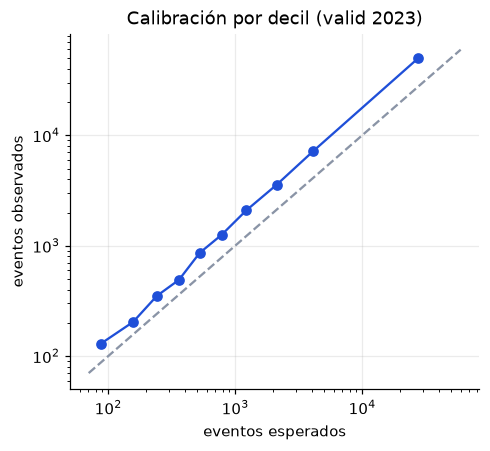

In [8]:
va = va.assign(r=M23[ELEGIDO].predict(va)); va["mu"] = va.r * va.expo
va["decil"] = pd.qcut(va.mu.rank(method="first"), 10, labels=False) + 1
cal = va.groupby("decil").agg(pred=("mu", "sum"), obs=("y_total", "sum")); cal["obs/pred"] = (cal.obs / cal.pred).round(2); print(cal.round(1).to_string())
va["cob_nivel"] = pd.cut(va.cobertura, [0, .6, .9, 1.01], labels=["baja (<60 %)", "media (60-90 %)", "alta (>90 %)"])
cb = va.groupby("cob_nivel").agg(cobertura=("cobertura", "mean"), pred=("mu", "sum"), obs=("y_total", "sum")); cb["obs/pred"] = (cb.obs / cb.pred).round(2); print("\n", cb.round(2).to_string())
print(f"\nTotal 2023: previsto {va.mu.sum():,.0f} · observado {va.y_total.sum():,.0f} · previsto/observado {va.mu.sum()/va.y_total.sum():.3f}")
fig, ax = plt.subplots(figsize=(4.8, 4.2)); ax.loglog(cal.pred, cal.obs, "o-", color=AZUL); lim = [cal.pred.min() * .8, cal.obs.max() * 1.2]; ax.plot(lim, lim, "--", color=GRIS)
ax.set(title="Calibración por decil (valid 2023)", xlabel="eventos esperados", ylabel="eventos observados"); guardar_fig("modelo_calibracion.png")

### Qué encontramos (calibración y sesgo, 2023)

- El modelo entrenado hasta 2022 **subpredice en todos los deciles**: observado/previsto va de 1,3 a 1,8. En total prevé 37 149 eventos y se observaron 65 919 (previsto/observado 0,56).
- Por nivel de cobertura de la comisaría, observado/previsto es 2,10 (baja, < 60 %), 1,68 (media) y 1,76 (alta): la subpredicción se parece entre niveles; no es un problema de cobertura sino del **salto de 66 % en la tasa de 2023**.
- La deriva del nivel se ve en las tres ventanas (previsto/observado 0,58, 0,65 y 0,56).

**Decisión:** el modelo sirve para **ordenar calles y comparar entornos**, no para dar cifras absolutas de eventos. En la app se muestran percentiles/escala 0–1 y siempre con la cobertura de la zona.

## 6. Riesgo por segmento para el ruteo — ¿qué vamos a hacer?

Se entrenan 4 modelos con el tipo elegido (total, noche, día y persona). Primero, solo con objetivos ≤ 2022, para predecir **2023**: ese riesgo sirve para elegir λ en el notebook de ruteo.
El riesgo se expresa como **densidad** (eventos esperados por km al año, largo mínimo de 50 m) y se lleva a 0–1 con `log1p(d)/log1p(p99)`, donde el p99 sale de esta predicción de validación
y se mantiene fijo para todas las predicciones siguientes (así la escala es la misma en validación, test y producción).

In [9]:
TARGETS = {"total": "y_total", "noche": "y_noche", "dia": "y_dia", "persona": "y_per"}
def densidad(r, largo): return r / (np.maximum(largo, 50) / 1000)
def esc01(d, ref): return np.clip(np.log1p(d) / np.log1p(ref), 0, 1)
out_v = va[["seg_id", "length_m", "expo", "y_total", "y_noche", "y_dia", "y_per", "cobertura"]].copy()
for k, y in TARGETS.items():
    m = M23[ELEGIDO] if k == "total" else Modelo(ELEGIDO, full_tv[full_tv.anio_obj <= 2022], y)
    out_v[f"r_{k}"] = m.predict(va); out_v[f"dens_{k}"] = densidad(out_v[f"r_{k}"], out_v.length_m)
REF = {k: float(out_v[f"dens_{k}"].quantile(.99)) for k in TARGETS}
for k in TARGETS: out_v[f"riesgo01_{k}"] = esc01(out_v[f"dens_{k}"], REF[k])
out_v.to_parquet(OUTD / "riesgo_valid2023.parquet", index=False)
print("referencia p99 de densidad (eventos/km·año):", {k: round(v, 1) for k, v in REF.items()})
print(out_v[[f"riesgo01_{k}" for k in TARGETS]].describe().round(3).to_string())

referencia p99 de densidad (eventos/km·año): {'total': 55.6, 'noche': 26.1, 'dia': 29.5, 'persona': 7.9}
       riesgo01_total  riesgo01_noche  riesgo01_dia  riesgo01_persona
count      146607.000      146607.000    146607.000        146607.000
mean            0.226           0.182         0.181             0.144
std             0.200           0.189         0.193             0.179
min             0.013           0.012         0.006             0.007
25%             0.076           0.053         0.047             0.036
50%             0.161           0.111         0.111             0.073
75%             0.318           0.247         0.247             0.174
max             1.000           1.000         1.000             1.000


### Qué encontramos (riesgo por segmento)

- Con los modelos entrenados hasta 2022, la referencia p99 de la densidad es **55,6 eventos por km y año** (noche 26,1; día 29,5; persona 7,9). El riesgo en escala 0–1 tiene media 0,226, mediana 0,161 y p90 0,498.
- Esa escala se **fija con el p99 de la validación 2023** y se usa igual en el test y en producción. Como el nivel de eventos subió, en esas etapas satura en 1 el 2,2 % (test) y el 2,0 % (producción) de los segmentos, en lugar del 1 % de la validación.
- Por tipo de vía (riesgo de producción), las **arteriales tienen el mayor riesgo medio (0,391)**; residencial 0,278, servicio 0,279, otras 0,275 y **peatonales 0,177**. Las arteriales concentran comercio y gente; no es un hallazgo sobre "calles malas".
- `riesgo_valid2023.parquet` (modelos hasta 2022, con los eventos reales de 2023) sirve para elegir λ en el ruteo.

**Decisión:** el costo de ruteo usa `riesgo01_total` de día y `riesgo01_noche` de noche.

## 7. EVALUACIÓN EN TEST (enero–agosto de 2024) — ¿qué vamos a hacer?

**Aquí se abre por primera vez `splits/test.parquet`.** El modelo, los hiperparámetros, las features y la escala del riesgo ya están fijados; no se cambia nada después de ver estos resultados.
El test pasa por **el mismo código** del EDA y del feature engineering (`marcar_calidad` con los puntos apilados de train, `filtrar_eje2`, `asignar_eventos`, `construir_panel`).

1. Comprobar que cada mes del test cumple la regla de cobertura (≥ 50 % de eventos relevantes con coordenada utilizable).
2. Entrenar con **todos los objetivos disponibles (2019–2023)** y predecir 2024 con features de años anteriores.
3. Medir contra los eventos reales de enero–agosto de 2024, con la exposición de esos 8 meses.

In [10]:
te = pd.read_parquet(SPL / "test.parquet")
apil = set(map(tuple, pd.read_parquet(CLEAN / "puntos_apilados.parquet").round(5).values))
te = C.marcar_calidad(te, apil); te["utilizable"] = te.coord_real & ~te.coord_apilada
rel_t = te[te.sirve_eje2]
mes_cob = rel_t.groupby(rel_t.fecha_hora_hecho.dt.strftime("%Y-%m")).utilizable.mean()
print("% de eventos relevantes con coordenada utilizable, por mes del test:", (mes_cob * 100).round(1).to_dict())
validos = [m for m, v in mes_cob.items() if v >= .5]
print(f"\nREGLA DE COBERTURA (>= 50 %): {len(validos)} de {len(mes_cob)} meses válidos -> evaluación formal {'POSIBLE' if len(validos) == len(mes_cob) else 'NO posible'}")
assert len(validos) == len(mes_cob), "algún mes del test no cumple la regla de cobertura"

% de eventos relevantes con coordenada utilizable, por mes del test: {'2024-01': 83.4, '2024-02': 84.4, '2024-03': 85.8, '2024-04': 82.8, '2024-05': 85.7, '2024-06': 88.0, '2024-07': 89.0, '2024-08': 88.1}

REGLA DE COBERTURA (>= 50 %): 8 de 8 meses válidos -> evaluación formal POSIBLE


**Lectura (cobertura del test):** los 8 meses de enero–agosto de 2024 tienen entre 82,8 % y 89,0 % de coordenada utilizable, así que la regla de cobertura se cumple y la evaluación formal es posible.

**Siguiente paso:** construir el panel del test con el mismo código del EDA y del feature engineering.

In [11]:
segz = gpd.read_parquet(FEAT / "segmentos_zona.parquet")
evs = pd.read_parquet(FEAT / "eventos_segmento.parquet"); seg_com = pd.read_parquet(FEAT / "segmento_comisaria.parquet")["comisaria"]
cob = pd.read_csv(CLEAN / "cobertura_comisaria_anio.csv"); bajos = set(pd.read_csv(CLEAN / "meses_baja_cobertura.csv").mes)
S = FE.matriz_vecindad(segz); poi = pd.read_parquet(FEAT / "poi_segmento.parquet")
cob24 = rel_t.groupby("comisaria_hecho").agg(cobertura=("utilizable", "mean")).reset_index().astype({"cobertura": float}).assign(anio=2024)
BAJOS_NO_OBS = {f"2024-{m:02d}" for m in range(9, 13)}                    # septiembre–diciembre de 2024 no están en el test
tu = C.filtrar_eje2(te); asig_t = FE.asignar_eventos(tu, segz, 40); ev_t = tu.merge(asig_t, on="id_dgc")
print(f"Test: {len(te):,} filas -> {len(tu):,} útiles -> {len(ev_t):,} asignadas a segmentos de la zona")
ev_all = pd.concat([evs, ev_t], ignore_index=True)
cob_all = pd.concat([cob, cob24[["comisaria_hecho", "anio", "cobertura"]]], ignore_index=True)
pt = FE.construir_panel(ev_all, segz, seg_com, S, cob_all, bajos | BAJOS_NO_OBS, anios_obj=[2024]).merge(poi.reset_index(), on="seg_id", how="left")
pt["prior_vec"] = pt.vec1 / pt.n_vec1.clip(lower=1)
print(f"Panel de test: {len(pt):,} segmentos · eventos objetivo {int(pt.y_total.sum()):,} · cobertura media {pt.cobertura.mean():.3f} · exposición media {pt.expo.mean():.3f}")

Test: 283,138 filas -> 91,918 útiles -> 47,350 asignadas a segmentos de la zona


Panel de test: 146,607 segmentos · eventos objetivo 47,350 · cobertura media 0.909 · exposición media 0.606


**Lectura (panel del test):** 283 138 denuncias → 91 918 útiles → 47 350 asignadas a segmentos de la zona; la exposición media es 0,606 (8 meses × cobertura).

**Siguiente paso:** entrenar con los objetivos 2019–2023 y medir una sola vez.

In [12]:
fin = {nm: Modelo(nm, full_tv) for nm in ("M1", "M2")}                     # entrenados con objetivos 2019-2023
filas = [evaluar("B0 constante", pt, np.full(len(pt), full_tv.y_total.sum() / full_tv.expo.sum())), evaluar("B1 historial del segmento", pt, r_b1(pt)),
         evaluar(f"B2 Empirical Bayes (K={K_EB})", pt, r_b2(pt, K_EB)), evaluar("M1 GLM Poisson", pt, fin["M1"].predict(pt)), evaluar("M2 LightGBM Poisson", pt, fin["M2"].predict(pt))]
rt = pd.DataFrame(filas).set_index("modelo"); print("TEST enero–agosto 2024:"); print(rt.to_string()); rt.to_csv(OUTD / "bakeoff_test2024.csv")
print("\nVentana 2023 (valid), para comparar:"); print(roll[roll.ventana == 2023].set_index("modelo")[["deviance", "spearman", "captura_top5%", "captura_top10%", "eventos_pred/obs"]].to_string())
pt["r"] = fin[ELEGIDO].predict(pt); pt["mu"] = pt.r * pt.expo; pt["decil"] = pd.qcut(pt.mu.rank(method="first"), 10, labels=False) + 1
cal_t = pt.groupby("decil").agg(pred=("mu", "sum"), obs=("y_total", "sum")); cal_t["obs/pred"] = (cal_t.obs / cal_t.pred).round(2); print("\n", cal_t.round(1).to_string())
pt["cob_nivel"] = pd.cut(pt.cobertura, [0, .6, .9, 1.01], labels=["baja (<60 %)", "media (60-90 %)", "alta (>90 %)"])
cbt = pt.groupby("cob_nivel").agg(cobertura=("cobertura", "mean"), pred=("mu", "sum"), obs=("y_total", "sum")); cbt["obs/pred"] = (cbt.obs / cbt.pred).round(2); print("\n", cbt.round(2).to_string())
# riesgo 2024 de los modelos entrenados con objetivos <= 2023 (para confirmar el ruteo en el notebook siguiente)
out_t = pt[["seg_id", "length_m", "expo", "y_total", "y_noche", "y_dia", "y_per", "cobertura"]].copy()
for k, y in TARGETS.items():
    m = fin[ELEGIDO] if k == "total" else Modelo(ELEGIDO, full_tv, y)
    out_t[f"r_{k}"] = m.predict(pt); out_t[f"dens_{k}"] = densidad(out_t[f"r_{k}"], out_t.length_m); out_t[f"riesgo01_{k}"] = esc01(out_t[f"dens_{k}"], REF[k])
out_t.to_parquet(OUTD / "riesgo_test2024.parquet", index=False)

TEST enero–agosto 2024:
                            deviance  MAE_conteo  spearman  captura_top5%  captura_top10%  eventos_pred/obs
modelo                                                                                                     
B0 constante                  2.2915      0.4845       NaN          0.036           0.083             0.620
B1 historial del segmento     0.9875      0.3127     0.460          0.671           0.785             0.674
B2 Empirical Bayes (K=0.5)    0.9921      0.4078     0.362          0.617           0.729             0.997
M1 GLM Poisson                0.7683      0.3539     0.394          0.675           0.782             1.003
M2 LightGBM Poisson           0.7012      0.3291     0.407          0.702           0.803             1.107

Ventana 2023 (valid), para comparar:
                            deviance  spearman  captura_top5%  captura_top10%  eventos_pred/obs
modelo                                                                                


           pred    obs  obs/pred
decil                          
1         73.9     44       0.6
2        132.8     58       0.4
3        209.5    111       0.5
4        320.3    199       0.6
5        481.5    400       0.8
6        733.0    710       1.0
7       1175.8   1177       1.0
8       2202.3   2054       0.9
9       4600.8   4712       1.0
10     42494.8  37885       0.9

                  cobertura      pred    obs  obs/pred
cob_nivel                                            
baja (<60 %)          0.49   4610.63   4399      0.95
media (60-90 %)       0.77  11488.70   9740      0.85
alta (>90 %)          0.98  36325.35  33211      0.91


### Qué encontramos (evaluación en test, enero–agosto de 2024)

- **La regla de cobertura se cumple:** los 8 meses del test tienen entre 82,8 % y 89,0 % de eventos relevantes con coordenada utilizable.
- 283 138 denuncias → 91 918 útiles → 47 350 asignadas a segmentos de la zona. Exposición media 0,606.

| Modelo | Deviance | MAE | Spearman | Captura top 5 % | Captura top 10 % | Previsto / observado |
|---|---:|---:|---:|---:|---:|---:|
| B0 constante | 2,292 | 0,485 | – | 3,6 % | 8,3 % | 0,62 |
| B1 historial del segmento | 0,988 | 0,313 | **0,460** | 67,1 % | 78,5 % | 0,67 |
| B2 Empirical Bayes | 0,992 | 0,408 | 0,362 | 61,7 % | 72,9 % | 1,00 |
| M1 GLM Poisson | 0,768 | 0,354 | 0,394 | 67,5 % | 78,2 % | **1,00** |
| **M2 LightGBM Poisson** | **0,701** | 0,329 | 0,407 | **70,2 %** | **80,3 %** | 1,11 |

- **LightGBM tiene la menor deviance** (29 % menos que el historial) y **captura 70,2 % de los eventos en el 5 % de calles** que marca como más riesgosas (historial 67,1 %, GLM 67,5 %).
- El historial vuelve a ordenar mejor el conjunto completo (Spearman 0,460 frente a 0,407), como en las ventanas.
- LightGBM **sobrepredice 11 %** el nivel; el GLM lo clava (1,00). Por decil, se sobrepredice en los bajos (previsto/observado de 0,4 a 0,6 en los deciles 1–4) y se acierta en los altos (0,9–1,0). Por nivel de cobertura: 0,95 (baja), 0,85 (media) y 0,91 (alta).
- Frente a las ventanas, la captura del test (70,2 %) es mayor que la de las ventanas (61–64 %). El test entrena con 5 años de objetivos y las ventanas con 2 a 4, lo que probablemente explica parte de la diferencia.

**Decisión:** nada se ajustó después de ver estos resultados. Se reporta el desempeño del test como el de referencia del modelo y se pasa a reentrenar con todos los datos para producción.

## 8. Modelos de producción e índice por punto de acceso — ¿qué vamos a hacer?

Con las decisiones ya cerradas, se **reentrena con todos los objetivos disponibles (2019–2023 y enero–agosto de 2024)** y se predice el riesgo del siguiente año con features que usan todos los eventos hasta agosto de 2024
(septiembre–diciembre de 2024 no se usan: cobertura insuficiente). Estos son los modelos y el riesgo que usará la app.

Para cada estación o paradero se resume su entorno de ~10 min con los **eventos esperados por km caminable al año**, `ER`. La app mostrará:

- **Seguridad %** = `100 × (1 − ER / ER_p95)` recortada a [0, 100]: 100 es un entorno sin riesgo esperado y 0 equivale al 5 % de accesos más riesgosos.
- **Base %**: la mediana de Seguridad % de los accesos *del mismo tipo* (Metro, troncal, corredor, alimentador).
- **Intervalo 90 %**: *bootstrap* de los segmentos del entorno.
- **Confianza** alta / media / baja según eventos históricos en el entorno, cobertura de coordenadas de la comisaría y qué tan bien está ubicado el punto (distancia al nodo de la red y, en alimentadores, `precision` de su coordenada).

Es **una aproximación con los datos que tenemos** (subregistro, cobertura desigual, ubicaciones de paraderos aproximadas) y así debe mostrarse.

In [13]:
prod_train = pd.concat([full_tv, pt[full_tv.columns.intersection(pt.columns)]], ignore_index=True)       # objetivos 2019-2023 + 2024 (ene-ago)
p25 = FE.construir_panel(ev_all, segz, seg_com, S, cob_all, bajos | BAJOS_NO_OBS, anios_obj=[2025]).merge(poi.reset_index(), on="seg_id", how="left")
p25["prior_vec"] = p25.vec1 / p25.n_vec1.clip(lower=1); p25["expo"] = 1.0; p25["cobertura"] = 1.0     # tasa a cobertura completa
out_p = p25[["seg_id", "length_m", "via", "n_eventos_pasado"]].copy(); mods_prod = {}
for k, y in TARGETS.items():
    m = Modelo(ELEGIDO, prod_train, y); mods_prod[k] = m
    out_p[f"r_{k}"] = m.predict(p25); out_p[f"dens_{k}"] = densidad(out_p[f"r_{k}"], out_p.length_m); out_p[f"riesgo01_{k}"] = esc01(out_p[f"dens_{k}"], REF[k])
out_p.to_parquet(OUTD / "riesgo_segmentos.parquet", index=False)
if ELEGIDO == "M2":
    for k, m in mods_prod.items(): m.g.save_model(str(MODD / f"lgbm_{k}_v1.txt"))
manifest = {"version": "eje2-v1.0", "objetivo": "eventos callejeros por segmento y año, corregidos por cobertura", "modelo": ELEGIDO, "features": NUM + ["via"],
            "params": PARAMS if ELEGIDO == "M2" else {"alpha": A_GLM}, "iteraciones": N_IT, "ref_p99_densidad": REF, "entrenado_con": "objetivos 2019-2023 y enero-agosto 2024",
            "features_de": "eventos hasta agosto de 2024", "K_EB": K_EB, "meses_baja_cobertura": sorted(bajos | BAJOS_NO_OBS), "metricas_test_2024": rt.loc["M2 LightGBM Poisson" if ELEGIDO == "M2" else "M1 GLM Poisson"].to_dict()}
(MODD / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=float))
print(f"riesgo de producción: {len(out_p):,} segmentos · modelos en {MODD}")
print(out_p.groupby("via").riesgo01_total.agg(["mean", "size"]).round(3).to_string())

riesgo de producción: 146,607 segmentos · modelos en /home/evssz/UTEC/6to/DPD/DPD_project/deliveries/week12/models/eje2
              mean   size
via                      
arterial     0.391  29355
otra         0.275    529
peatonal     0.177  51600
residencial  0.278  56403
servicio     0.279   8720


**Lectura (producción):** se reentrenó con objetivos 2019–2023 y enero–agosto de 2024 y se predijo el siguiente año con eventos hasta agosto de 2024; las arteriales tienen el mayor riesgo medio y las peatonales el menor.

**Siguiente paso:** resumir el entorno de cada estación o paradero en el índice de seguridad.

In [14]:
acc = pd.read_parquet(FEAT / "puntos_acceso.parquet"); memb = pd.read_parquet(FEAT / "acceso_segmentos.parquet"); snap = pd.read_parquet(FEAT / "acceso_snap.parquet")["snap_m"]
rk = out_p.set_index("seg_id")
m = memb.merge(rk[["length_m", "r_total", "n_eventos_pasado"]], left_on="seg_id", right_index=True)
cob_ref = cob_all[cob_all.anio == 2024].set_index("comisaria_hecho").cobertura
m["cob"] = m.seg_id.map(seg_com.map(cob_ref)).fillna(.7)
rng = np.random.default_rng(SEED)
filas = []
for aid, g in m.groupby("acceso_id"):
    km = g.length_m.values / 1000; r = g.r_total.values
    er = r.sum() / km.sum()
    bs = [(r[i].sum() / km[i].sum()) for i in (rng.integers(0, len(g), len(g)) for _ in range(200))]
    filas.append((aid, len(g), km.sum(), er, np.percentile(bs, 5), np.percentile(bs, 95), g.n_eventos_pasado.sum(), g.cob.mean()))
ix = pd.DataFrame(filas, columns=["acceso_id", "n_seg", "km", "ER", "ER_lo", "ER_hi", "eventos_pasado", "cobertura"]).merge(acc, on="acceso_id")
ix["snap_m"] = ix.acceso_id.map(snap)
P95 = ix.ER.quantile(.95)
seg_pct = lambda er: (100 * (1 - np.clip(er / P95, 0, 1)))
ix["seguridad_pct"] = seg_pct(ix.ER); ix["seg_lo"] = seg_pct(ix.ER_hi); ix["seg_hi"] = seg_pct(ix.ER_lo)
ix["base_tipo_pct"] = ix.groupby("tipo").seguridad_pct.transform("median"); ix["vs_base"] = ix.seguridad_pct - ix.base_tipo_pct
def conf(r):
    pts = 0
    pts += 2 if r.eventos_pasado >= 200 else 1 if r.eventos_pasado >= 50 else 0
    pts += 2 if r.cobertura >= .8 else 1 if r.cobertura >= .5 else 0
    pts += 0 if r.snap_m > 150 else 1 if r.snap_m > 60 else 2
    if r.tipo == "alimentador" and r.precision_coord == "aproximada": pts -= 1
    return "alta" if pts >= 5 else "media" if pts >= 3 else "baja"
ix["confianza"] = ix.apply(conf, axis=1)
ix.drop(columns=["geometry"], errors="ignore").to_parquet(OUTD / "indice_puntos_acceso.parquet", index=False)
res_t = ix.groupby("tipo").agg(n=("acceso_id", "size"), seguridad_mediana=("seguridad_pct", "median"), base=("base_tipo_pct", "first"),
                              ancho_intervalo_medio=("seg_hi", lambda s: float((s - ix.loc[s.index, "seg_lo"]).mean())),
                              pct_conf_alta=("confianza", lambda s: (s == "alta").mean() * 100), pct_conf_baja=("confianza", lambda s: (s == "baja").mean() * 100)).round(1)
print(res_t.to_string())
print("\nEjemplos (con su base e intervalo):")
ej = ix.sort_values("seguridad_pct").iloc[[0, len(ix) // 4, len(ix) // 2, 3 * len(ix) // 4, -1]]
print(ej[["tipo", "nombre", "seguridad_pct", "seg_lo", "seg_hi", "base_tipo_pct", "confianza"]].round(0).to_string(index=False))
res_t.to_csv(OUTD / "indice_por_tipo.csv")

               n  seguridad_mediana  base  ancho_intervalo_medio  pct_conf_alta  pct_conf_baja
tipo                                                                                          
alimentador  712               95.2  95.2                    6.3           44.7            7.3
corredor     993               68.0  68.0                   19.8           96.6            0.0
metro_l1      26               71.2  71.2                   20.5          100.0            0.0
troncal       44               54.5  54.5                   19.4           88.6            0.0

Ejemplos (con su base e intervalo):
       tipo              nombre  seguridad_pct  seg_lo  seg_hi  base_tipo_pct confianza
    troncal   Jiron de la Unión            0.0     0.0     0.0           55.0      alta
alimentador Hospital Los Olivos           60.0    45.0    73.0           95.0      alta
   corredor              Celima           79.0    63.0    97.0           68.0     media
   corredor                CIAM          

### Qué encontramos (índice por punto de acceso)

| Tipo | Puntos | Seguridad mediana (= base del tipo) | Ancho medio del intervalo 90 % | Confianza alta | Confianza baja |
|---|---:|---:|---:|---:|---:|
| Alimentador | 712 | 95,2 % | 6,3 | 44,7 % | 7,3 % |
| Corredor | 993 | 68,0 % | 19,8 | 96,6 % | 0 % |
| Metro L1 | 26 | 71,2 % | 20,5 | 100 % | 0 % |
| Troncal (Metropolitano) | 44 | 54,5 % | 19,4 | 88,6 % | 0 % |

Ejemplos: *Jirón de la Unión* (troncal) **0 %** frente a una base de 55 % (de los accesos con más riesgo esperado); *Hospital Los Olivos* (alimentador) 60 % (45–73) frente a una base de 95 %; *Celima* (corredor) 79 % (63–97) frente a 68 %, con confianza media; *CIAM* (corredor) 94 % (93–96) frente a 68 %.

- **Los alimentadores salen "muy seguros" (95,2 %) casi seguro por una razón de datos**: son entornos periféricos con menos denuncias registradas y menos coordenadas utilizables. Aquí "seguridad" significa **menos denuncias esperadas**, no menos delito.
- Los intervalos de alimentadores son angostos (6,3) porque casi todo su entorno tiene riesgo esperado cercano a cero; los de Metro, corredor y troncal son anchos (≈ 20) porque hay calles muy distintas dentro de 800 m.
- 57 % de los alimentadores tiene coordenada aproximada y 7,3 % termina con confianza baja.
- Los modelos de producción se entrenaron con objetivos 2019–2023 y enero–agosto de 2024 y predicen con eventos hasta agosto de 2024.

**Decisión:** mostrar siempre "Seguridad X % (intervalo) frente a una base de Y % del mismo tipo" y la etiqueta de confianza, con el texto "estimación aproximada con denuncias registradas". Nunca se presenta como probabilidad de ser víctima.

### Conclusiones

1. **LightGBM Poisson con offset de exposición** gana en las tres ventanas móviles (deviance media 0,786, 28 % menos que el historial) y en el test de enero–agosto de 2024 (deviance 0,701; el 5 % de calles de mayor riesgo captura el **70,2 %** de los eventos).
2. El **historial reciente del propio segmento** es la señal dominante; la **vecindad** y el **largo** aportan en las tres ventanas y los **POIs** casi nada (+0,0004).
3. **El nivel de eventos no se predice bien** (previsto/observado de 0,56 a 0,65 en las ventanas por el crecimiento anual, 1,11 en el test): se usa para ordenar y comparar, no para dar cifras absolutas.
4. El índice por punto de acceso se muestra con **base del mismo tipo, intervalo de 90 % y etiqueta de confianza**. Los alimentadores salen más "seguros" sobre todo por menos registro, y esto debe decirse.
5. Las decisiones (modelo, bloques de features) siguieron reglas fijadas antes de mirar los resultados y se tomaron solo con 2021–2023; el test se midió una sola vez.
6. Sesgos que siguen vigentes: subregistro, quién denuncia, cobertura desigual entre comisarías y coordenadas aproximadas de paraderos.